# E-Commerce Sales & Customer Analysis

**Author:** Gayatri Deshmukh

## Objective
Explore sales, profitability, customer contribution, regions,
discounts, payment methods, and order statuses.

## Dataset
Global E-Commerce Sales Dataset, 2021–2024.
This is synthetic learning data.

Source:
https://www.kaggle.com/datasets/abdelfattahibrahim/global-e-commerce-sales-dataset-20212024

## Reporting scope
Financial analysis includes all order statuses.
Recorded revenue is not delivered-only or refund-adjusted revenue.
Customers are identified by ID because names are unavailable.

## Workflow
Load → Inspect → Clean → Transform → Analyze → Visualize → Interpret

In [15]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

# Support execution from either the project root or notebooks folder.
current_directory = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        directory
        for directory in [current_directory, *current_directory.parents]
        if (directory / "src" / "config.py").is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Open this notebook from inside Ecommerce_EDA_Project."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import CLEAN_FILE, GRAPH_DIR, CHART_FILENAMES
from src.data_loader import load_data
from src.data_cleaning import clean_data
from src.data_transformation import transform_data
from src.analysis import analyze_data
from src.visualization import create_visualizations

pd.set_option("display.max_columns", 35)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

print("Project root:", PROJECT_ROOT)
print("Python interpreter:", sys.executable)

Project root: C:\Projects\Ecommerce_EDA_Project
Python interpreter: c:\Projects\Ecommerce_EDA_Project\.venv\Scripts\python.exe


## 1. Load and Inspect

Inspect dimensions, data types, missing values, and duplicates
before making changes. The raw CSV is preserved.

In [16]:
raw_df = load_data()

display(raw_df.head())
display(raw_df.describe(include="all").T)

missing_summary = pd.DataFrame({
    "missing_count": raw_df.isna().sum(),
    "missing_percent": raw_df.isna().mean() * 100,
})

display(missing_summary)


--- DATASET OVERVIEW ---
Rows: 10,000
Columns: 26

Column names:
['order_id', 'order_date', 'year', 'month', 'quarter', 'season', 'customer_id', 'customer_gender', 'customer_segment', 'region', 'country', 'category', 'sub_category', 'product', 'unit_price', 'quantity', 'discount', 'sales', 'cost', 'profit', 'source_profit_margin_pct', 'shipping_cost', 'shipping_method', 'shipping_days', 'payment_method', 'order_status']

First 5 rows:
  order_id order_date  year  month quarter season customer_id customer_gender customer_segment        region country      category sub_category                product  unit_price  quantity  discount    sales     cost   profit  source_profit_margin_pct  shipping_cost shipping_method  shipping_days payment_method order_status
ORD-000001 2023-01-18  2023      1      Q1 Winter  CUST-02791            Male              New North America  Mexico   Electronics  Smartphones              Xiaomi 13      520.40         7      0.00 3,642.80 2,444.11 1,198.69         

,order_id,order_date,year,month,quarter,season,customer_id,customer_gender,customer_segment,region,country,category,sub_category,product,unit_price,quantity,discount,sales,cost,profit,source_profit_margin_pct,shipping_cost,shipping_method,shipping_days,payment_method,order_status
0,ORD-000001,2023-01-18,2023,1,Q1,Winter,CUST-02791,Male,New,North America,Mexico,Electronics,Smartphones,Xiaomi 13,520.40,7,0.00,"3,642.80","2,444.11","1,198.69",32.91,2.25,Economy,4,Google Pay,Delivered
1,ORD-000002,2023-11-13,2023,11,Q4,Fall,CUST-02763,Female,Regular,North America,USA,Books & Media,Books,Thinking Fast and Slow,22.59,2,0.25,33.88,28.32,5.56,16.41,4.72,Economy,5,Credit Card,Delivered
2,ORD-000003,2022-04-28,2022,4,Q2,Spring,CUST-05729,Male,Regular,North America,Canada,Electronics,Headphones,Bose QC45,241.30,1,0.00,241.30,161.41,79.89,33.11,13.28,Standard,8,Credit Card,Processing
3,ORD-000004,2021-10-22,2021,10,Q4,Fall,CUST-06490,Female,Regular,Asia,Japan,Clothing,Women's Wear,Summer Dress,130.90,5,0.00,654.50,369.16,285.34,43.60,31.11,Express,16,Google Pay,Processing
4,ORD-000005,2023-08-06,2023,8,Q3,Summer,CUST-07594,Female,Premium,Europe,France,Clothing,Footwear,Adidas Ultraboost,74.51,3,0.20,178.82,118.69,60.13,33.63,8.44,Standard,5,Debit Card,Delivered


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,10000,10000,ORD-000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,10000,1355,2023-10-14,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,"10,000.00",NaN,NaN,NaN,"2,022.76",0.88,"2,021.00","2,022.00","2,023.00","2,023.00","2,024.00"
month,"10,000.00",NaN,NaN,NaN,6.60,3.41,1.00,4.00,7.00,10.00,12.00
quarter,10000,4,Q3,2594,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,10000,4,Summer,2600,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,10000,5348,CUST-02229,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_gender,10000,2,Female,5097,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_segment,10000,4,Regular,5073,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,10000,4,North America,2602,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,missing_count,missing_percent
order_id,0,0.00
order_date,0,0.00
year,0,0.00
month,0,0.00
quarter,0,0.00
season,0,0.00
customer_id,0,0.00
customer_gender,0,0.00
customer_segment,0,0.00
region,0,0.00


## 2. Clean and Transform

Cleaning validates dates, numeric values, required fields,
duplicates, and discount rates.

Negative profits are retained because they represent recorded losses.
Unusual values are not automatically removed.

Transformation creates time fields, revenue, row profit margins,
and discount categories. Discounts are already reflected in sales.

In [17]:
clean_df = clean_data(raw_df)
eda_df = transform_data(clean_df)

cleaning_audit = pd.Series(
    clean_df.attrs["cleaning_summary"],
    name="Count",
)

display(cleaning_audit.to_frame())

display(
    eda_df[
        [
            "order_id",
            "year_month",
            "revenue",
            "profit",
            "profit_margin_pct",
            "discount_category",
        ]
    ].head()
)


--- CLEANING SUMMARY ---
Input rows: 10,000
Exact duplicates removed: 0
Missing or invalid essential rows removed: 0
Invalid transaction rows removed: 0
Categorical values filled: 0
Missing discount filled with zero: 0
Missing profit filled with zero: 0
Invalid discount rows removed: 0
Duplicates after standardization removed: 0
Output rows: 10,000
Total rows removed: 0

Required-column missing values after cleaning:
order_id          0
order_date        0
customer_id       0
product           0
category          0
region            0
sales             0
quantity          0
discount          0
profit            0
payment_method    0
order_status      0

Key data types after cleaning:
order_date    datetime64[us]
sales                float64
quantity               int64
discount             float64
profit               float64

Negative-profit rows retained: 1338

--- TRANSFORMATION SUMMARY ---
Rows: 10,000
Columns: 31
Date range: 2021-01-05 to 2024-12-24

Discount category counts:
dis

,Count
input_rows,10000
exact_duplicates_removed,0
missing_or_invalid_essential_rows_removed,0
invalid_transaction_rows_removed,0
categorical_values_filled,0
missing_discount_filled_with_zero,0
missing_profit_filled_with_zero,0
invalid_discount_rows_removed,0
duplicates_after_standardization_removed,0
output_rows,10000


,order_id,year_month,revenue,profit,profit_margin_pct,discount_category
0,ORD-000001,2023-01,"3,642.80","1,198.69",32.91,No Discount
1,ORD-000002,2023-11,33.88,5.56,16.41,High (>20%)
2,ORD-000003,2022-04,241.30,79.89,33.11,No Discount
3,ORD-000004,2021-10,654.50,285.34,43.60,No Discount
4,ORD-000005,2023-08,178.82,60.13,33.63,Medium (10-20%]


## 3. Business Analysis

- AOV = total revenue ÷ distinct orders.
- Overall profit margin = total profit ÷ total revenue × 100.
- Overall margin is not the average of individual row margins.
- Cancellation and return counts use distinct order IDs.

In [18]:
summaries = analyze_data(eda_df)

display(
    pd.Series(summaries["kpis"], name="Value")
    .rename_axis("Metric")
    .to_frame()
)

for title, key in [
    ("Regional performance", "region_revenue"),
    ("Category performance", "category_revenue"),
    ("Top customers", "top_customers"),
    ("Top products", "product_sales"),
    ("Monthly performance", "monthly_revenue"),
    ("Payment usage", "payment_method"),
    ("Order statuses", "status_counts"),
    ("Discount groups", "discount_profit"),
    ("Lowest total-profit products", "weak_products"),
]:
    display(Markdown(f"### {title}"))
    display(summaries[key].head(10))


--- BUSINESS KPI SUMMARY ---
Analysis scope: All order statuses
Total revenue: 5,284,387.70
Total profit: 1,437,638.31
Unique orders: 10,000
Average order value: 528.44
Overall profit margin: 27.21%
Cancelled orders, all records: 908
Returned orders, all records: 1,857

Revenue by region:
       region      revenue     profit  unique_orders  quantity  profit_margin_pct
  Middle East 1,348,593.22 384,522.85           2458      6634              28.51
North America 1,331,129.75 366,717.42           2602      7167              27.55
         Asia 1,330,007.18 350,413.48           2494      6859              26.35
       Europe 1,274,657.55 335,984.56           2446      6653              26.36

Profit by category:
       category      revenue     profit  unique_orders  quantity  profit_margin_pct
    Electronics 3,382,028.46 925,448.15           1977      5287              27.36
 Home & Kitchen   892,842.02 232,421.45           2008      5535              26.03
       Clothing   407,471.

,Value
Metric,
total_revenue,"5,284,387.70"
total_profit,"1,437,638.31"
unique_orders,10000
unique_customers,5348
aov,528.44
profit_margin_pct,27.21
cancelled,908
returned,1857
analyzed_rows,10000


### Regional performance

,region,revenue,profit,unique_orders,quantity,profit_margin_pct
0,Middle East,"1,348,593.22","384,522.85",2458,6634,28.51
1,North America,"1,331,129.75","366,717.42",2602,7167,27.55
2,Asia,"1,330,007.18","350,413.48",2494,6859,26.35
3,Europe,"1,274,657.55","335,984.56",2446,6653,26.36


### Category performance

,category,revenue,profit,unique_orders,quantity,profit_margin_pct
0,Electronics,"3,382,028.46","925,448.15",1977,5287,27.36
1,Home & Kitchen,"892,842.02","232,421.45",2008,5535,26.03
2,Clothing,"407,471.79","115,705.29",1977,5375,28.40
3,Books & Media,"386,644.46","105,037.69",2043,5667,27.17
4,Beauty & Health,"215,400.97","59,025.73",1995,5449,27.40


... (10 outputs left out)

### Discount groups

,discount_category,revenue,profit,average_profit,order_rows,profit_margin_pct
0,No Discount,"1,784,476.34","722,282.06",267.51,2700,40.48
1,Low (0-10%],"1,043,530.17","376,740.84",204.42,1843,36.10
2,Medium (10-20%],"920,641.03","258,693.63",144.93,1785,28.10
3,High (>20%),"1,535,740.16","79,921.78",21.77,3672,5.20


### Lowest total-profit products

,product,revenue,profit,unique_orders,quantity,profit_margin_pct
0,Thinking Fast and Slow,"10,353.83","2,772.83",189,504,26.78
1,The Psychology of Money,"11,335.81","2,951.70",203,590,26.04
2,Deep Work,"11,996.11","3,015.08",206,576,25.13
3,Rich Dad Poor Dad,"11,462.37","3,049.67",213,569,26.61
4,Atomic Habits,"12,181.12","3,403.63",211,580,27.94
5,Classic T-Shirt,"15,792.03","4,403.26",118,307,27.88
6,Whey Protein 2kg,"18,399.26","4,639.78",192,488,25.22
7,Slim Fit Jeans,"18,256.18","4,707.26",121,343,25.78
8,Chino Pants,"18,640.64","4,920.75",129,362,26.40
9,Vitamin D3,"19,874.70","5,039.37",200,504,25.36


## 4. Univariate and Multivariate Exploration

Summary statistics describe numerical distributions.
Frequency tables describe categorical variables.

The IQR rule flags potential outliers for inspection.
It does not prove that a record is incorrect.

In [19]:
display(summaries["numeric_summary"])

for column in ["category", "region", "discount_category"]:
    display(Markdown(f"### {column} frequencies"))
    display(eda_df[column].value_counts().to_frame("Rows"))

# Flag unusually small or large revenue values using the IQR rule.
q1 = eda_df["revenue"].quantile(0.25)
q3 = eda_df["revenue"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

potential_outliers = eda_df.loc[
    ~eda_df["revenue"].between(lower_bound, upper_bound)
]

print("Potential revenue outlier rows:", len(potential_outliers))
print("These records remain in the analysis.")

display(
    potential_outliers[
        ["order_id", "product", "revenue", "profit"]
    ]
    .sort_values("revenue", ascending=False)
    .head(10)
)

display(Markdown("### Numerical correlations"))
display(summaries["correlation"])

,count,mean,std,min,25%,50%,75%,max
revenue,"10,000.00",528.44,"1,154.81",5.33,67.23,164.60,469.95,"19,966.50"
quantity,"10,000.00",2.73,2.04,1.00,1.00,2.00,4.00,10.00
discount,"10,000.00",0.18,0.16,0.00,0.00,0.15,0.30,0.50
profit,"10,000.00",143.76,420.49,"-1,572.90",9.01,34.75,118.47,"9,144.15"
profit_margin_pct,"10,000.00",23.65,21.50,-50.00,13.50,28.33,39.09,54.99


### category frequencies

,Rows
category,
Books & Media,2043
Home & Kitchen,2008
Beauty & Health,1995
Electronics,1977
Clothing,1977


### region frequencies

,Rows
region,
North America,2602
Asia,2494
Middle East,2458
Europe,2446


### discount_category frequencies

,Rows
discount_category,
High (>20%),3672
No Discount,2700
Low (0-10%],1843
Medium (10-20%],1785


Potential revenue outlier rows: 1177
These records remain in the analysis.


,order_id,product,revenue,profit
265,ORD-000266,Dell XPS 15,"19,966.50","8,722.18"
604,ORD-000605,Lenovo ThinkPad X1,"19,246.08","3,516.41"
8101,ORD-008102,Dell XPS 15,"19,017.04","8,859.76"
2993,ORD-002994,Lenovo ThinkPad X1,"16,901.36","9,144.15"
9017,ORD-009018,ASUS ZenBook,"16,056.69","4,674.65"
2122,ORD-002123,MacBook Air M2,"15,142.47","6,685.26"
8403,ORD-008404,MacBook Air M2,"14,855.47","5,789.20"
6594,ORD-006595,ASUS ZenBook,"14,010.25","4,789.13"
9366,ORD-009367,MacBook Air M2,"13,398.93","6,373.05"
4140,ORD-004141,Dell XPS 15,"13,366.14",680.70


### Numerical correlations

,revenue,quantity,discount,profit,profit_margin_pct
revenue,1.00,0.33,-0.09,0.85,0.08
quantity,0.33,1.00,0.00,0.25,0.00
discount,-0.09,0.00,1.00,-0.25,-0.83
profit,0.85,0.25,-0.25,1.00,0.28
profit_margin_pct,0.08,0.00,-0.83,0.28,1.00


## 5. Visual Analysis

The ten charts cover univariate, bivariate, and multivariate analysis.
They use the same reporting scope as the business summaries.

Correlation describes association, not causation.

Saved: revenue_by_region.png
Saved: revenue_by_category.png
Saved: profit_by_category.png
Saved: monthly_revenue_trend.png
Saved: top_customers.png
Saved: discount_vs_profit.png
Saved: revenue_distribution.png
Saved: profit_margin_boxplot.png
Saved: correlation_heatmap.png
Saved: payment_method_usage.png

All 10 chart files are present.
Chart folder: C:\Projects\Ecommerce_EDA_Project\outputs\graphs


### Revenue By Region

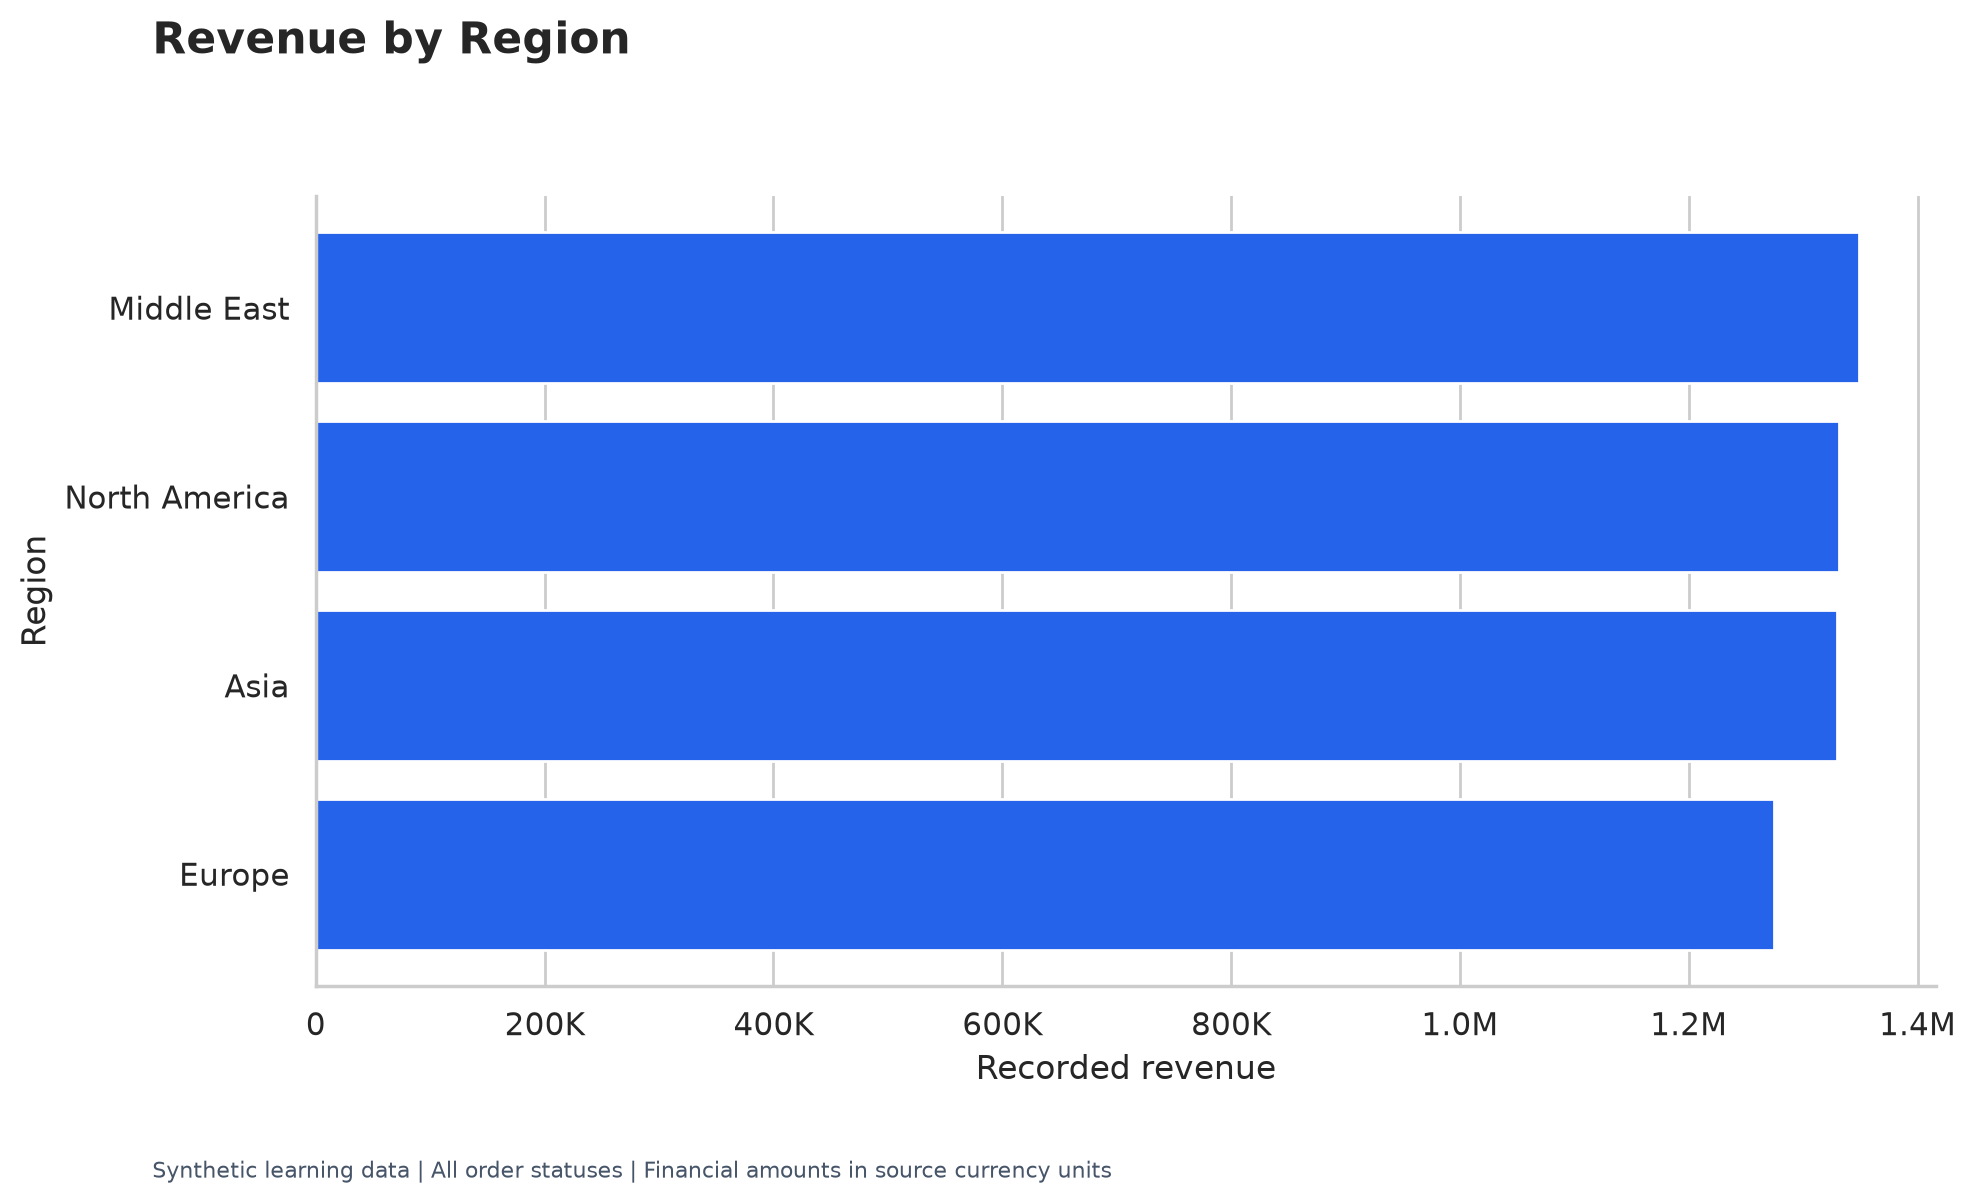

### Revenue By Category

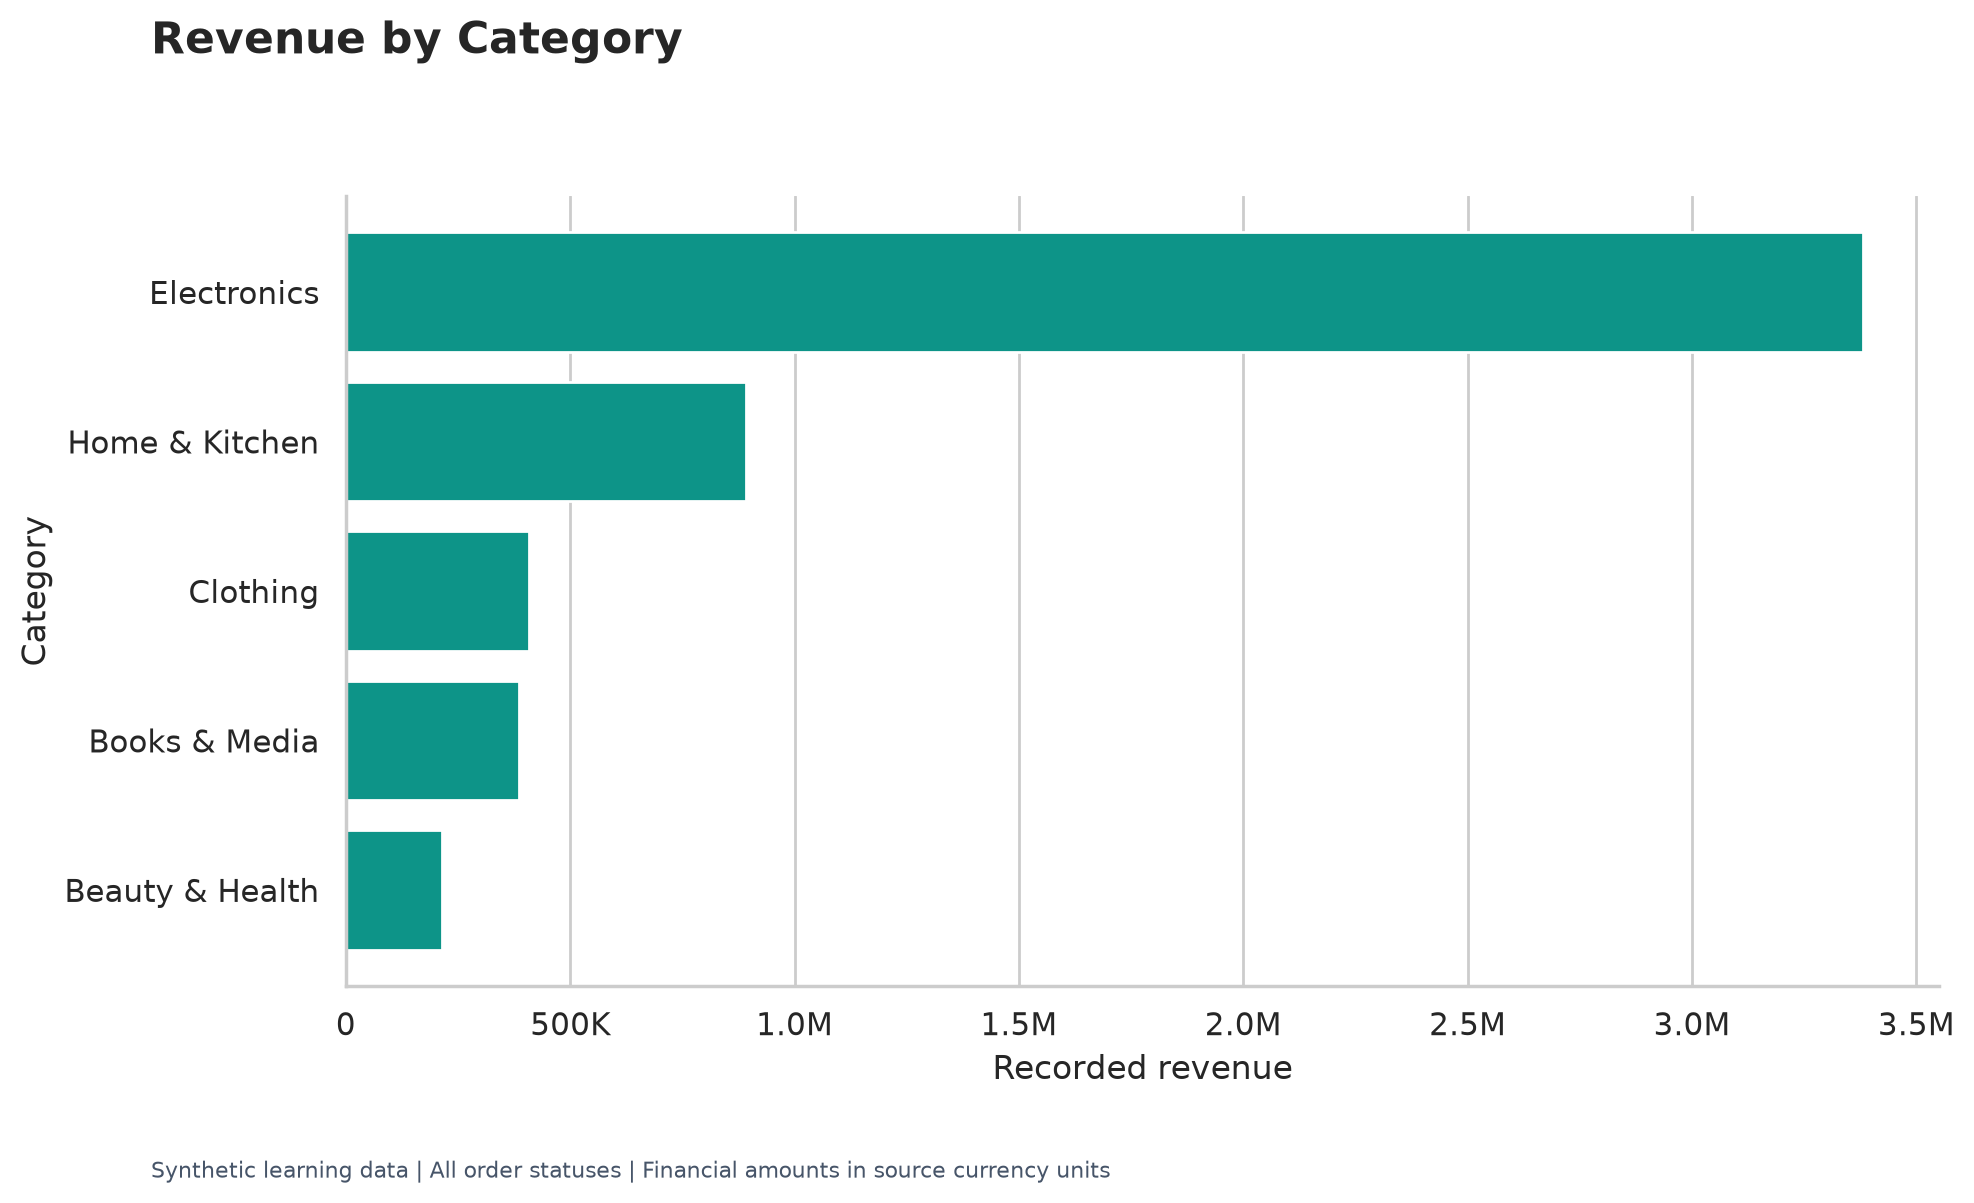

### Profit By Category

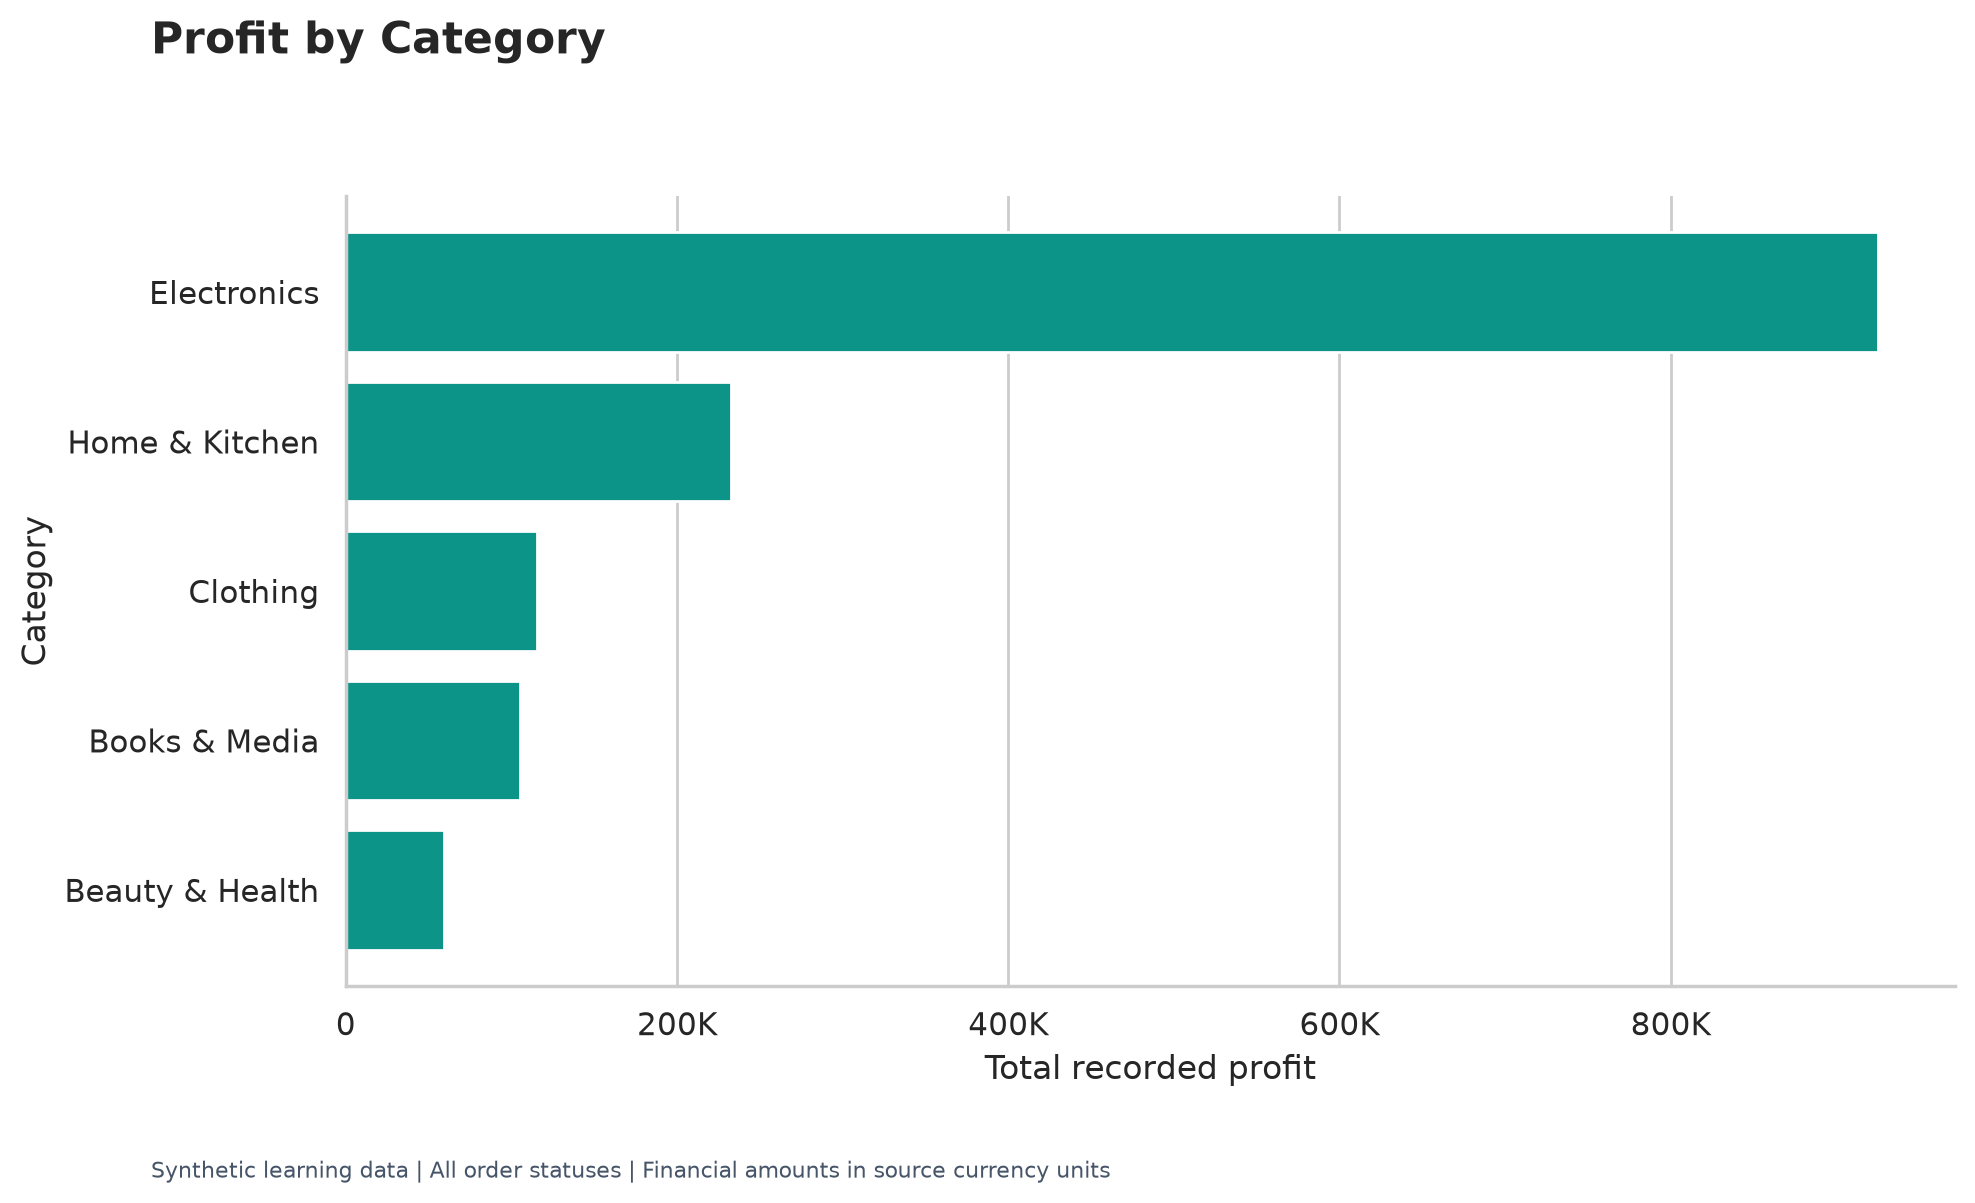

### Monthly Revenue Trend

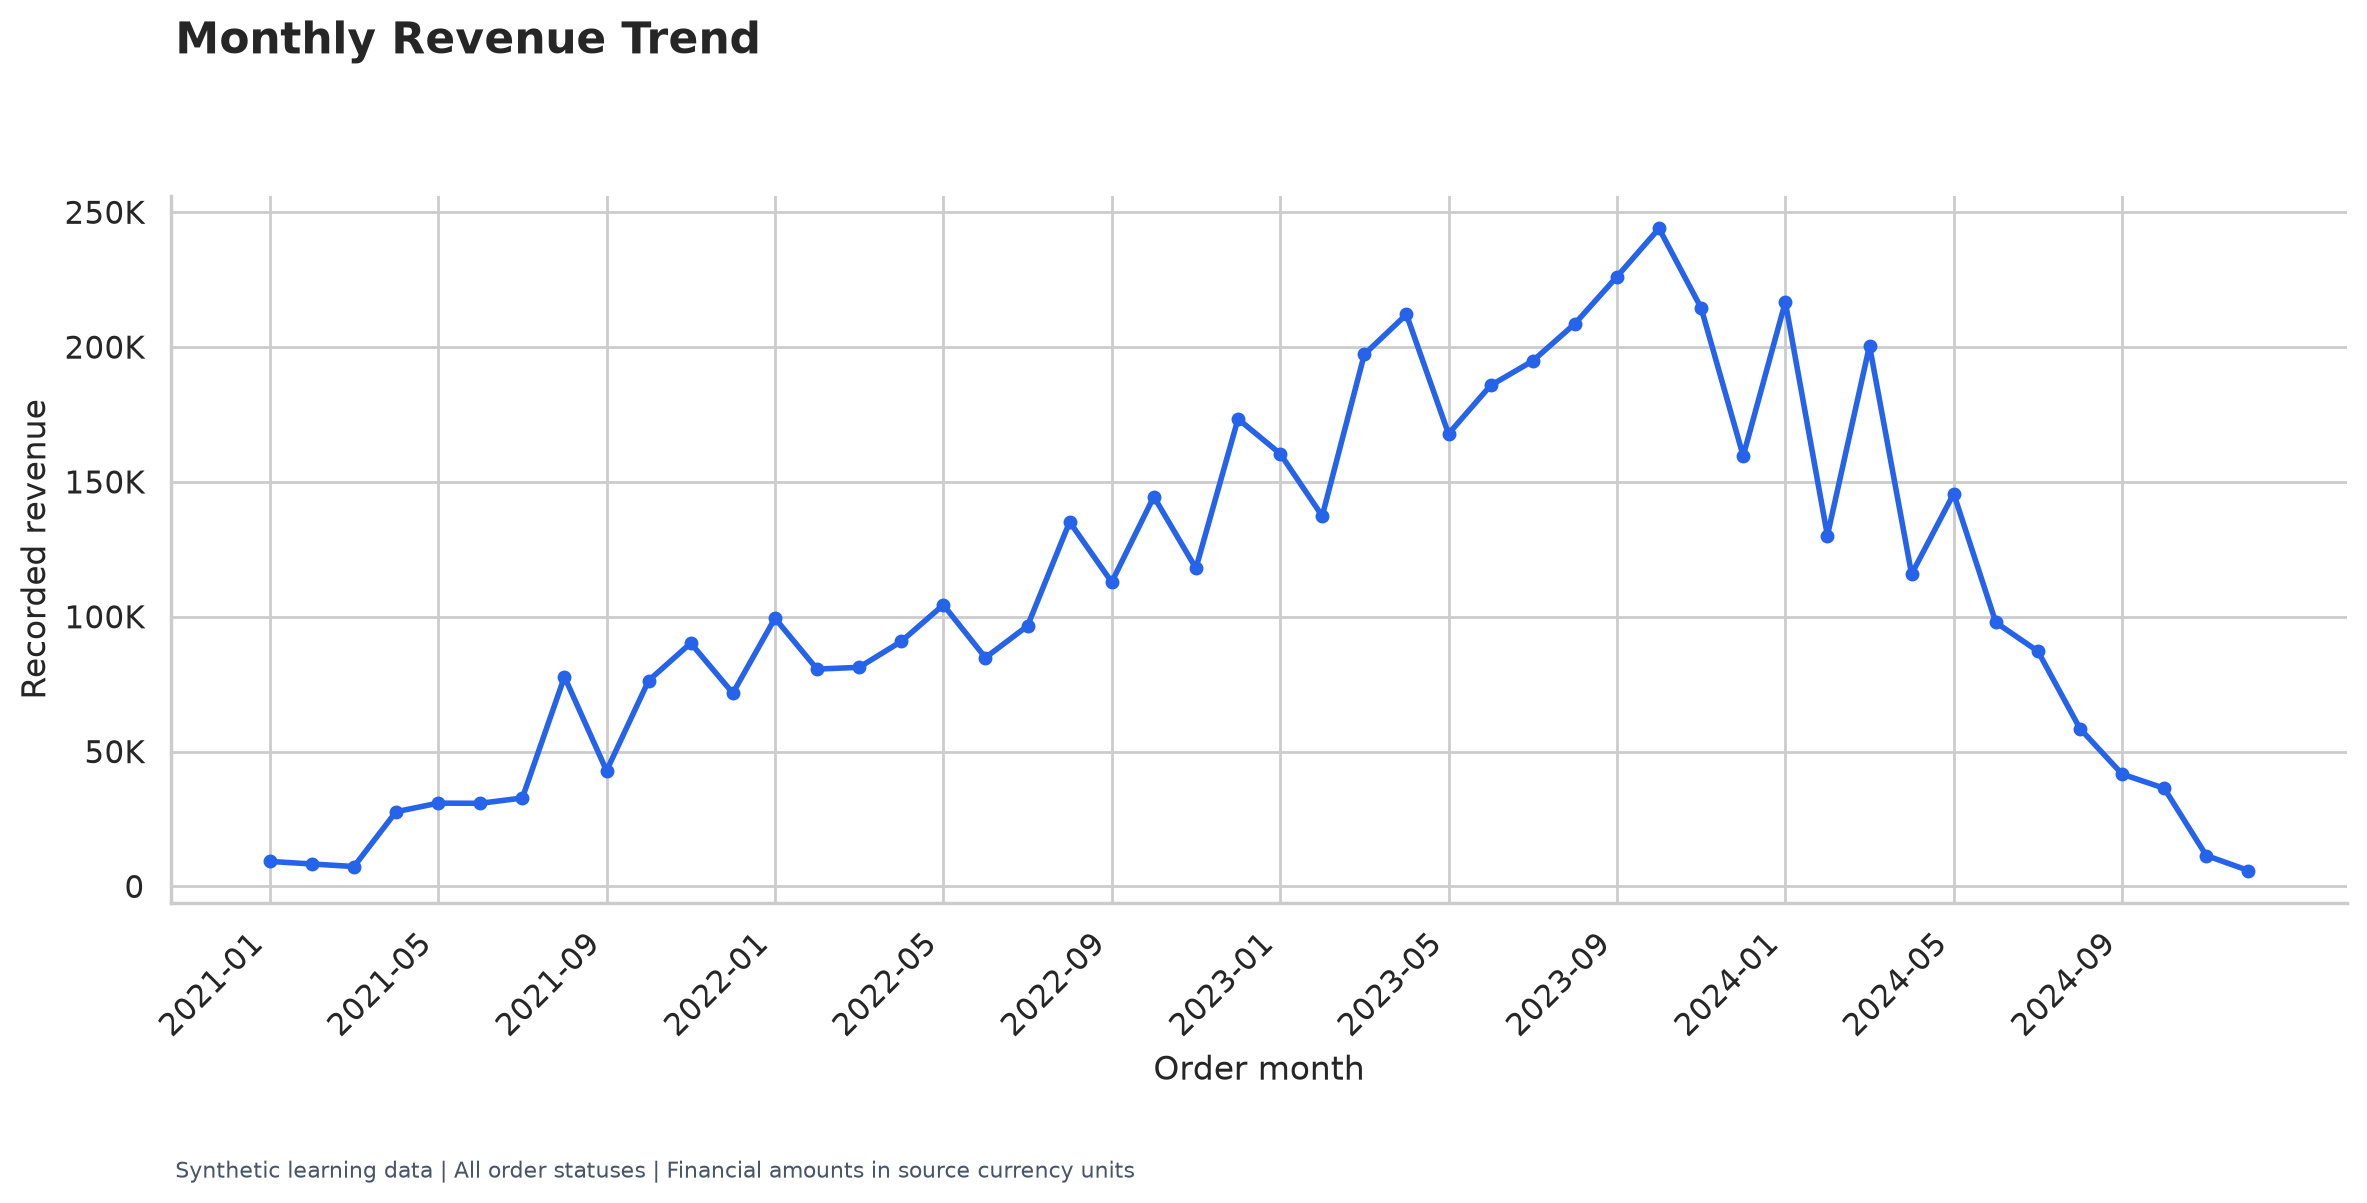

### Top Customers

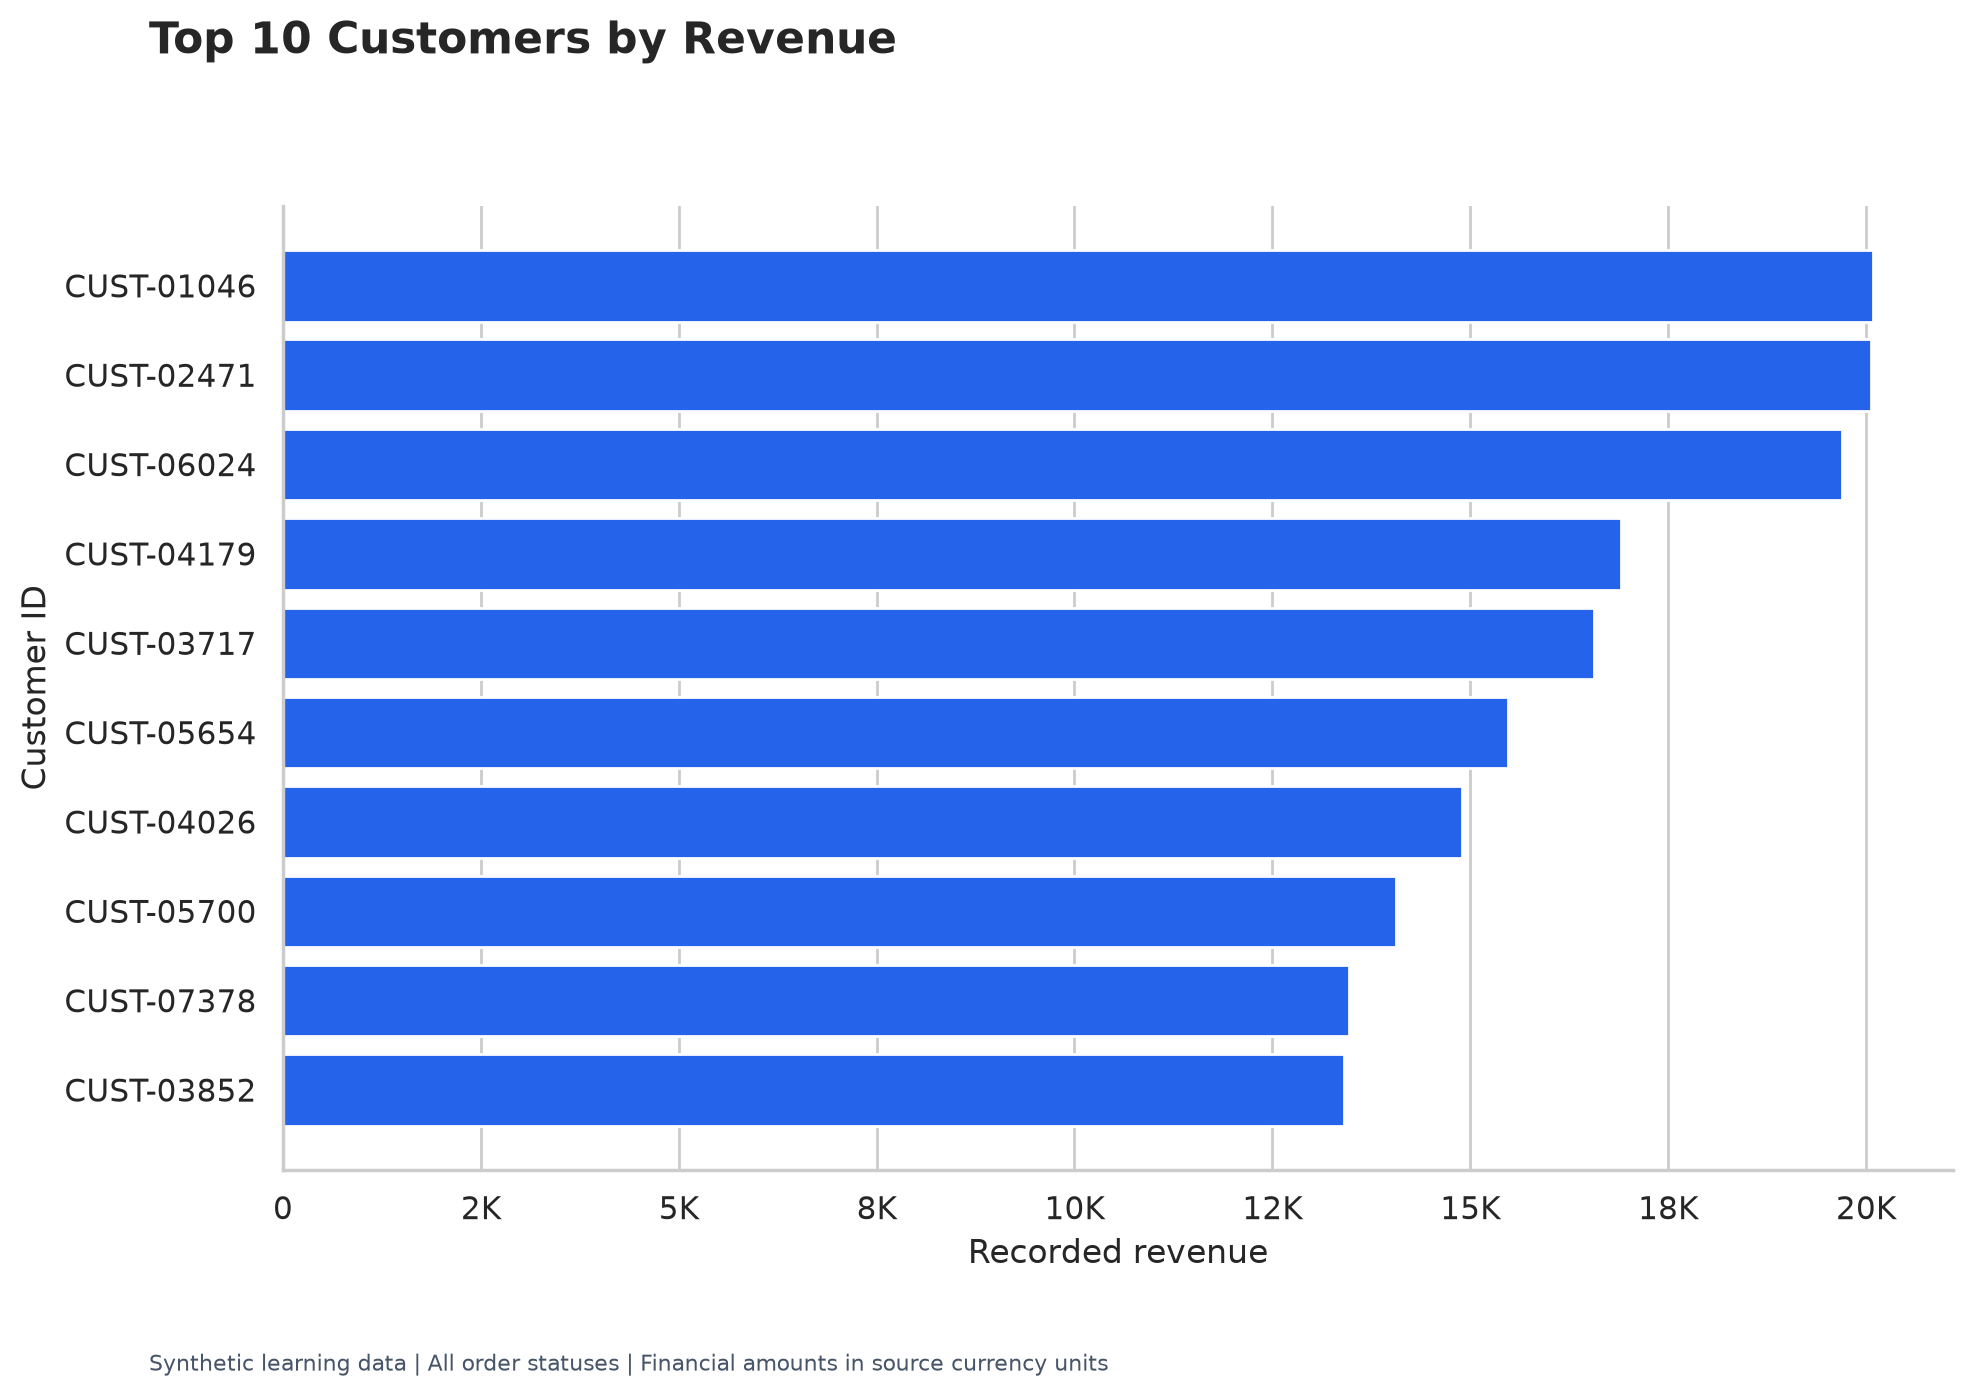

### Discount Vs Profit

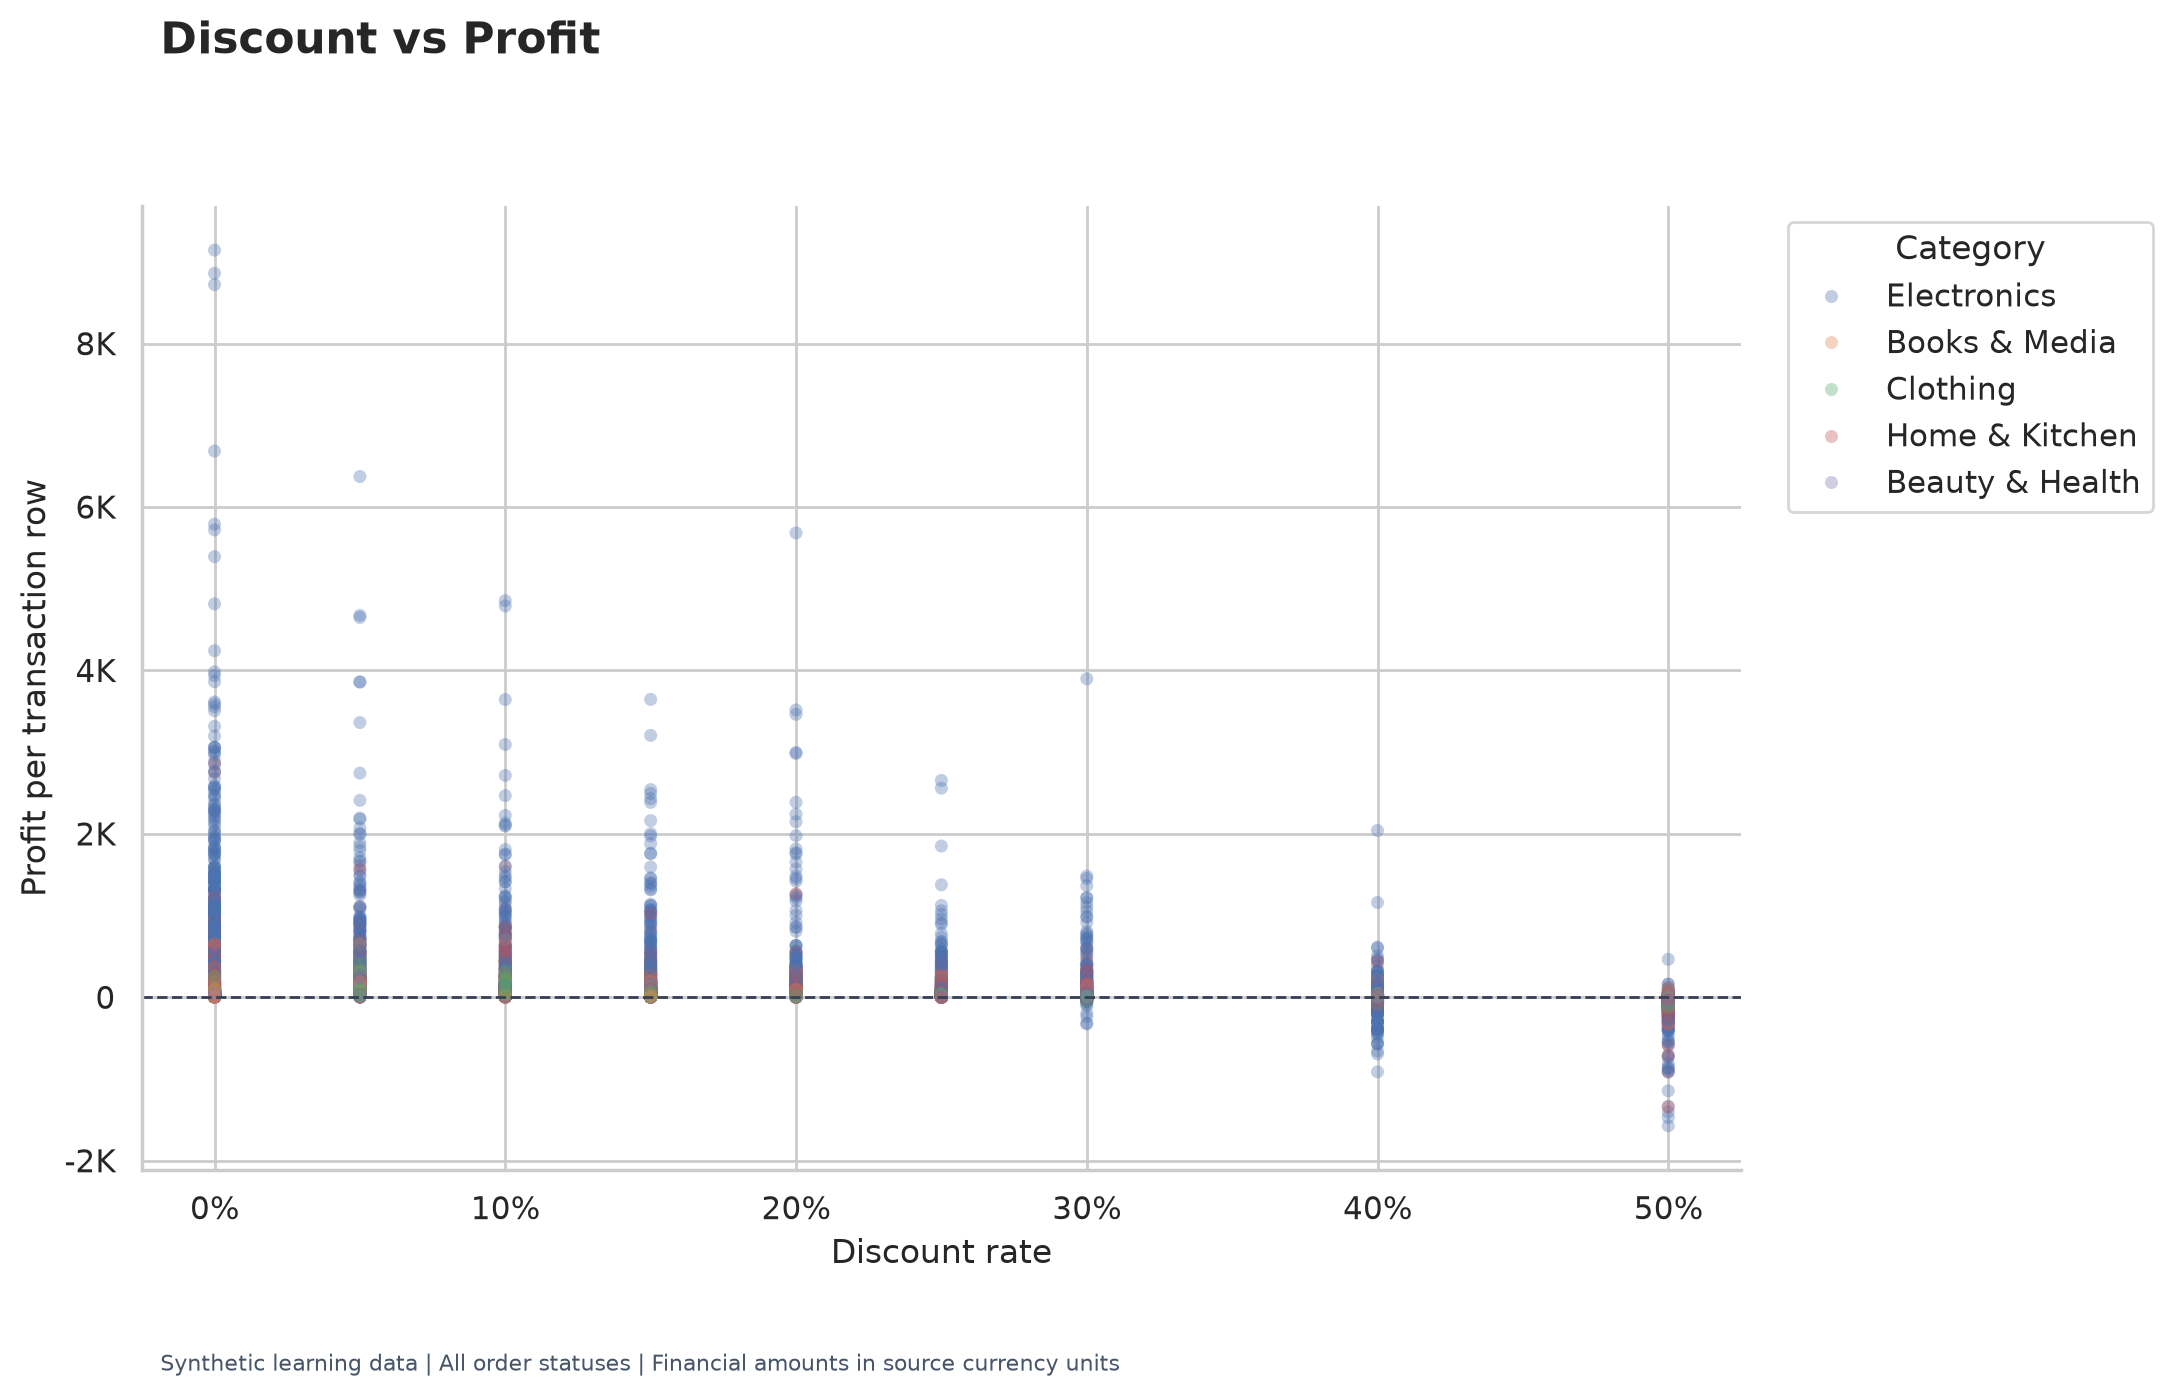

### Revenue Distribution

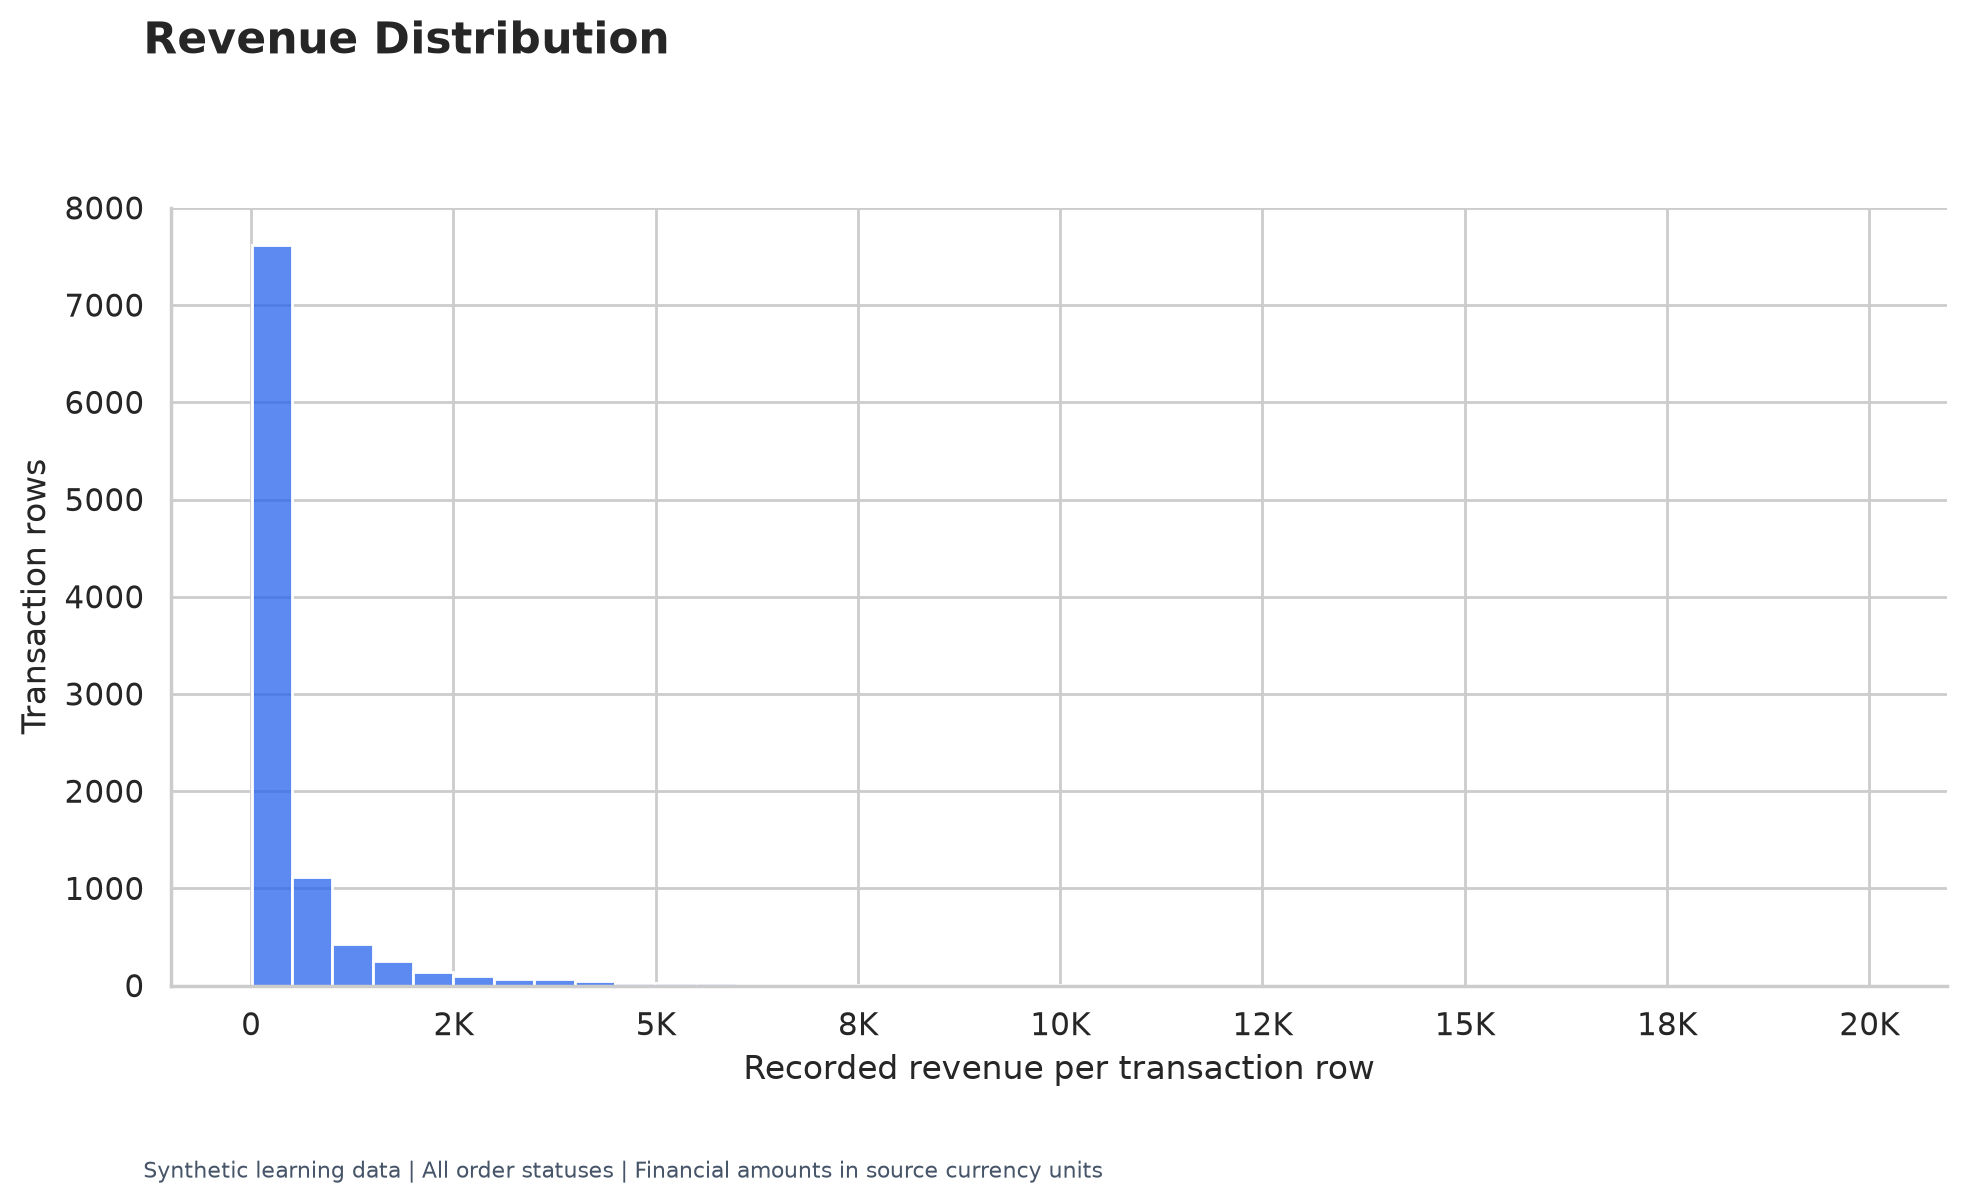

### Profit Margin Boxplot

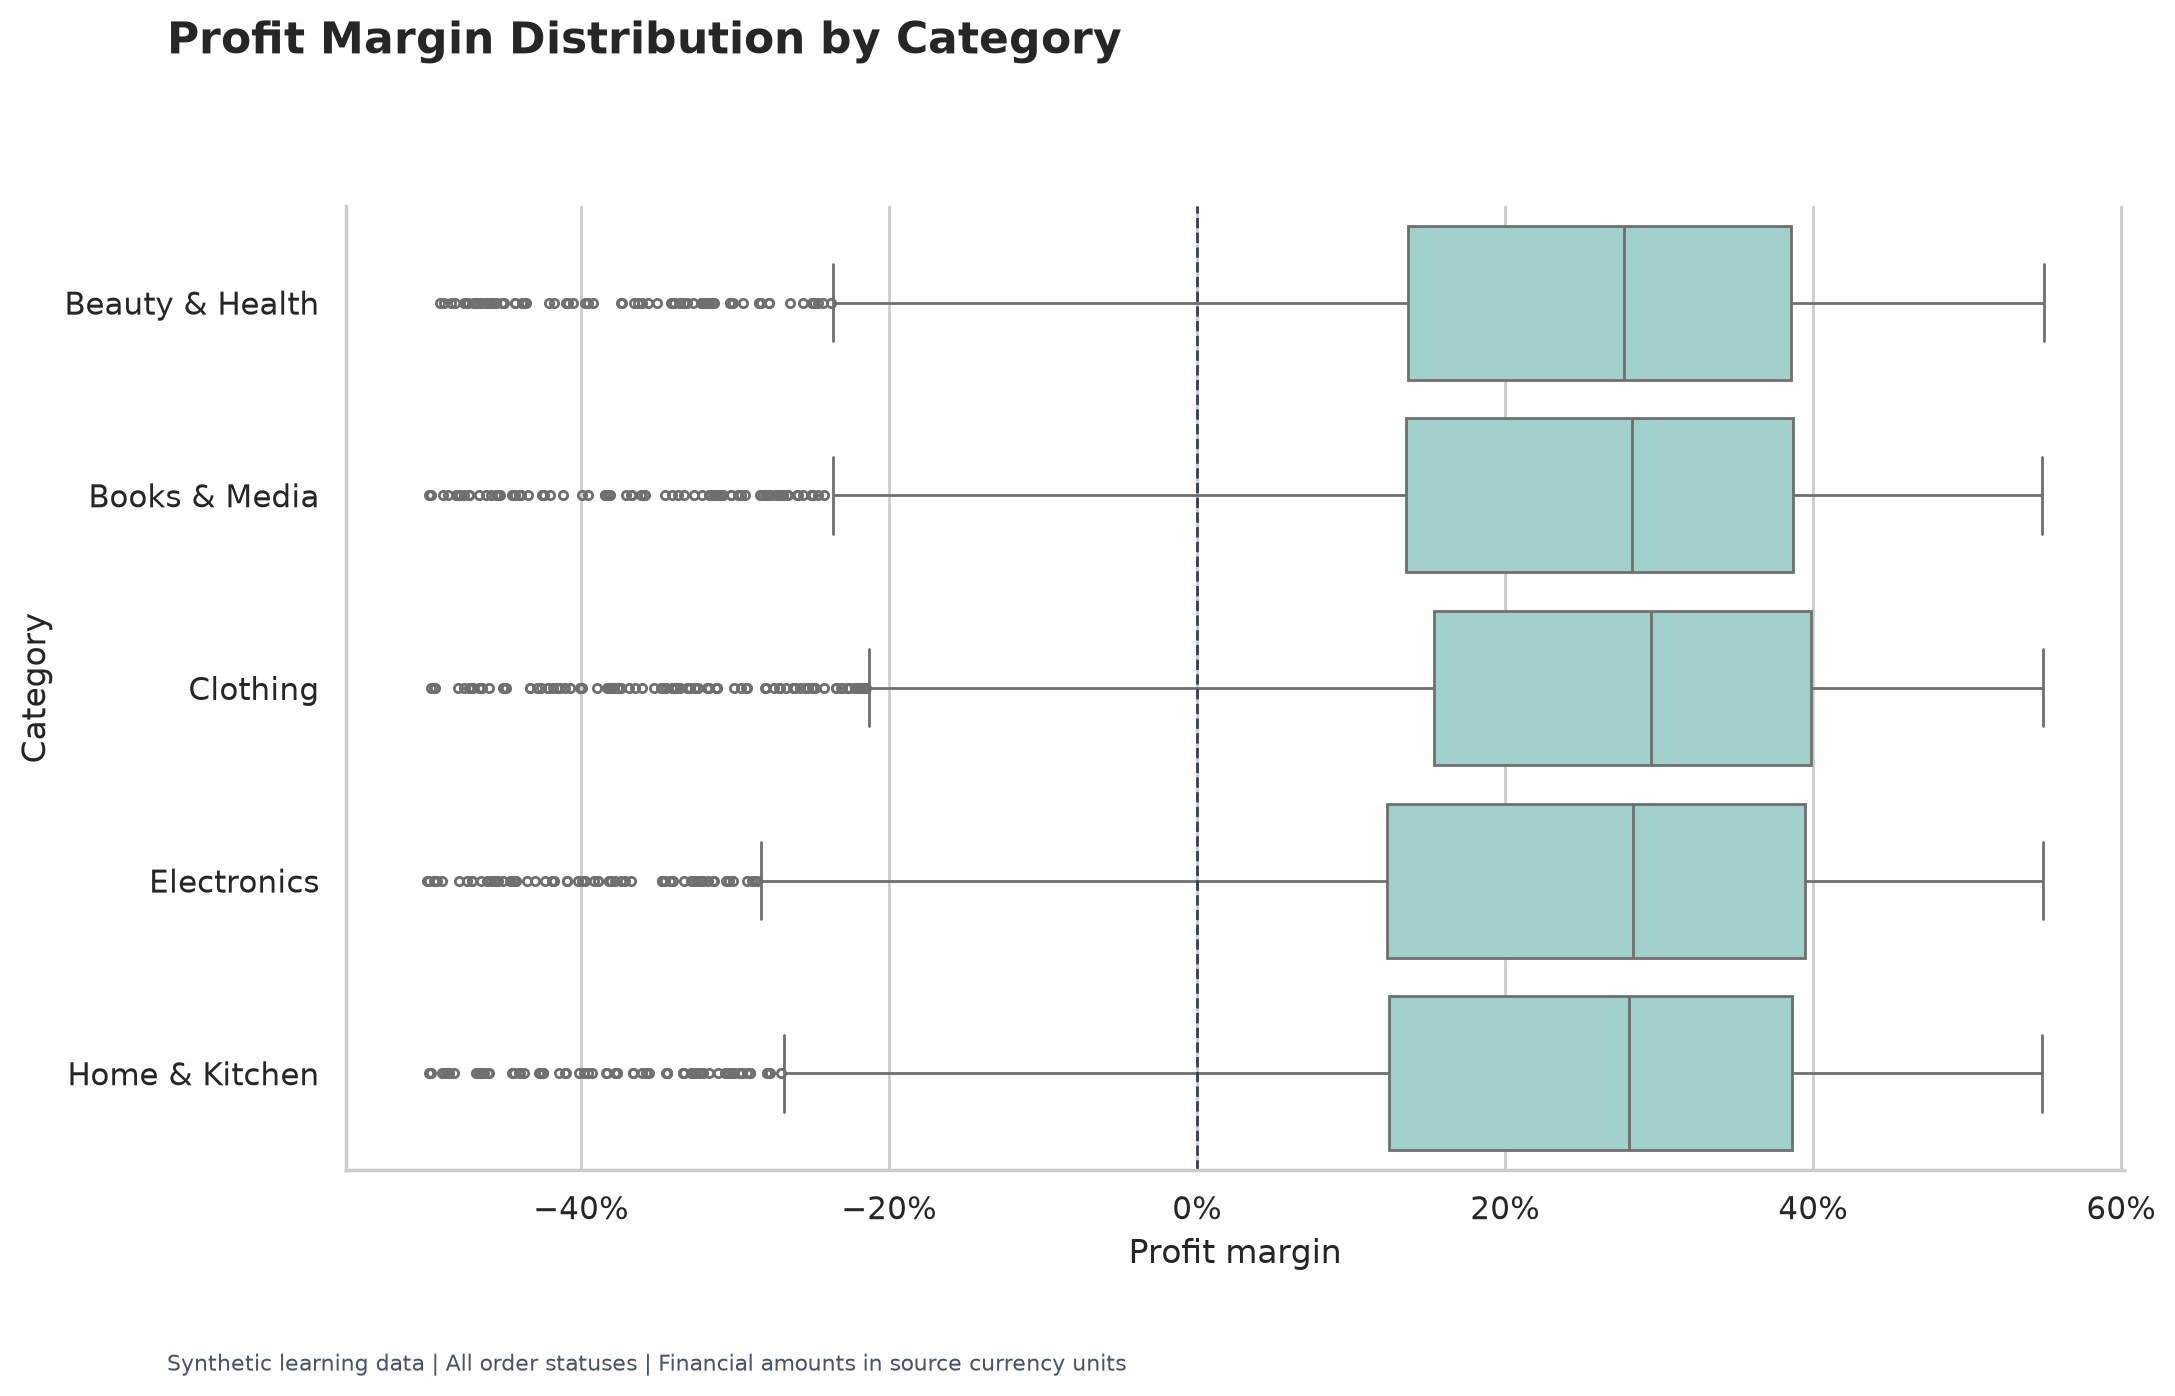

### Correlation Heatmap

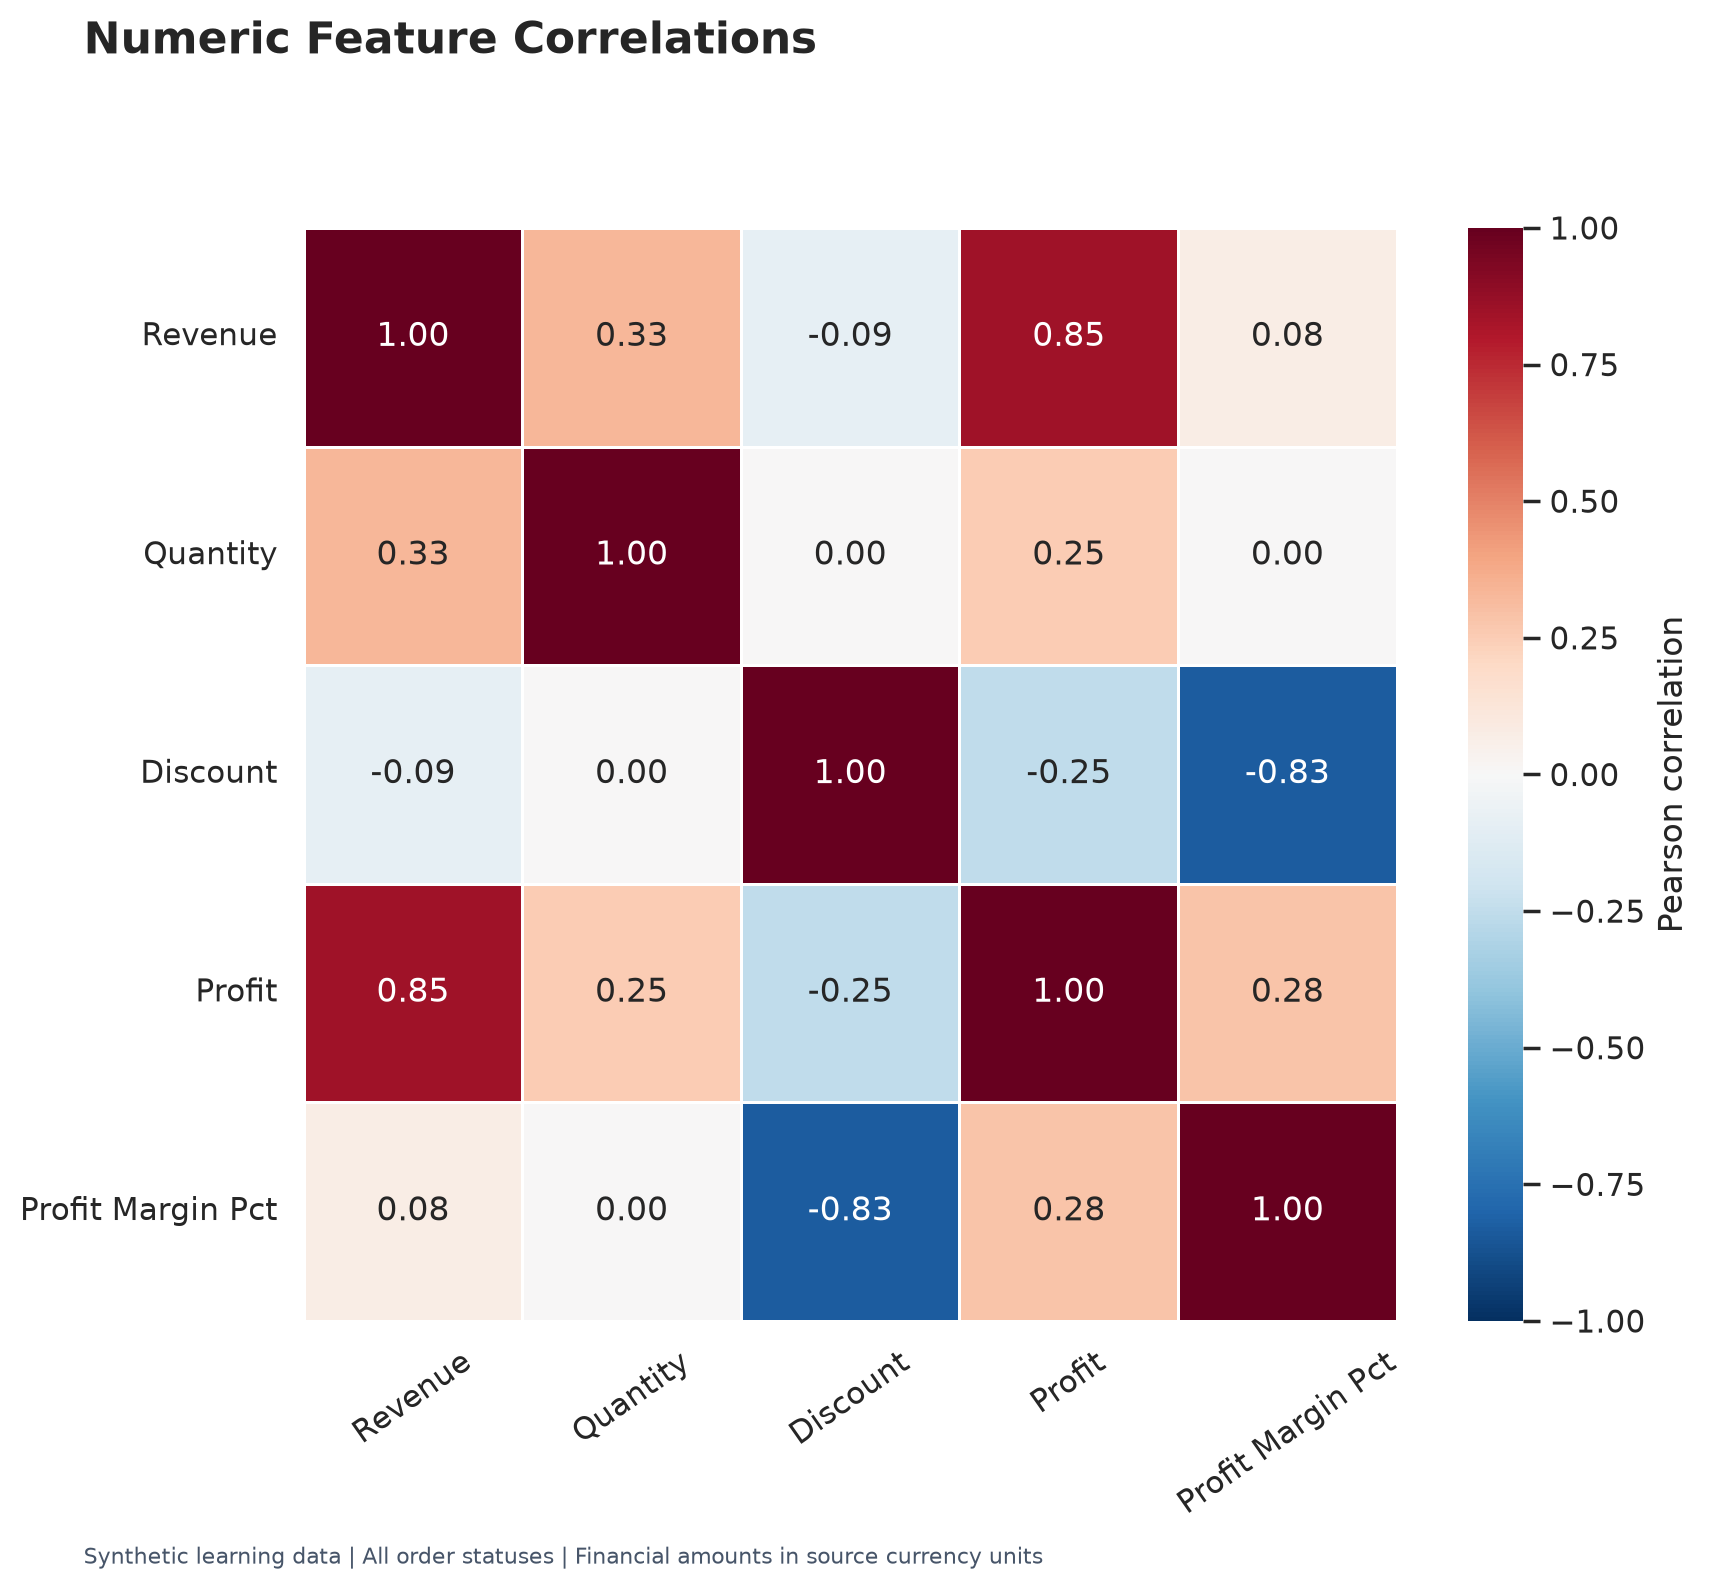

### Payment Method Usage

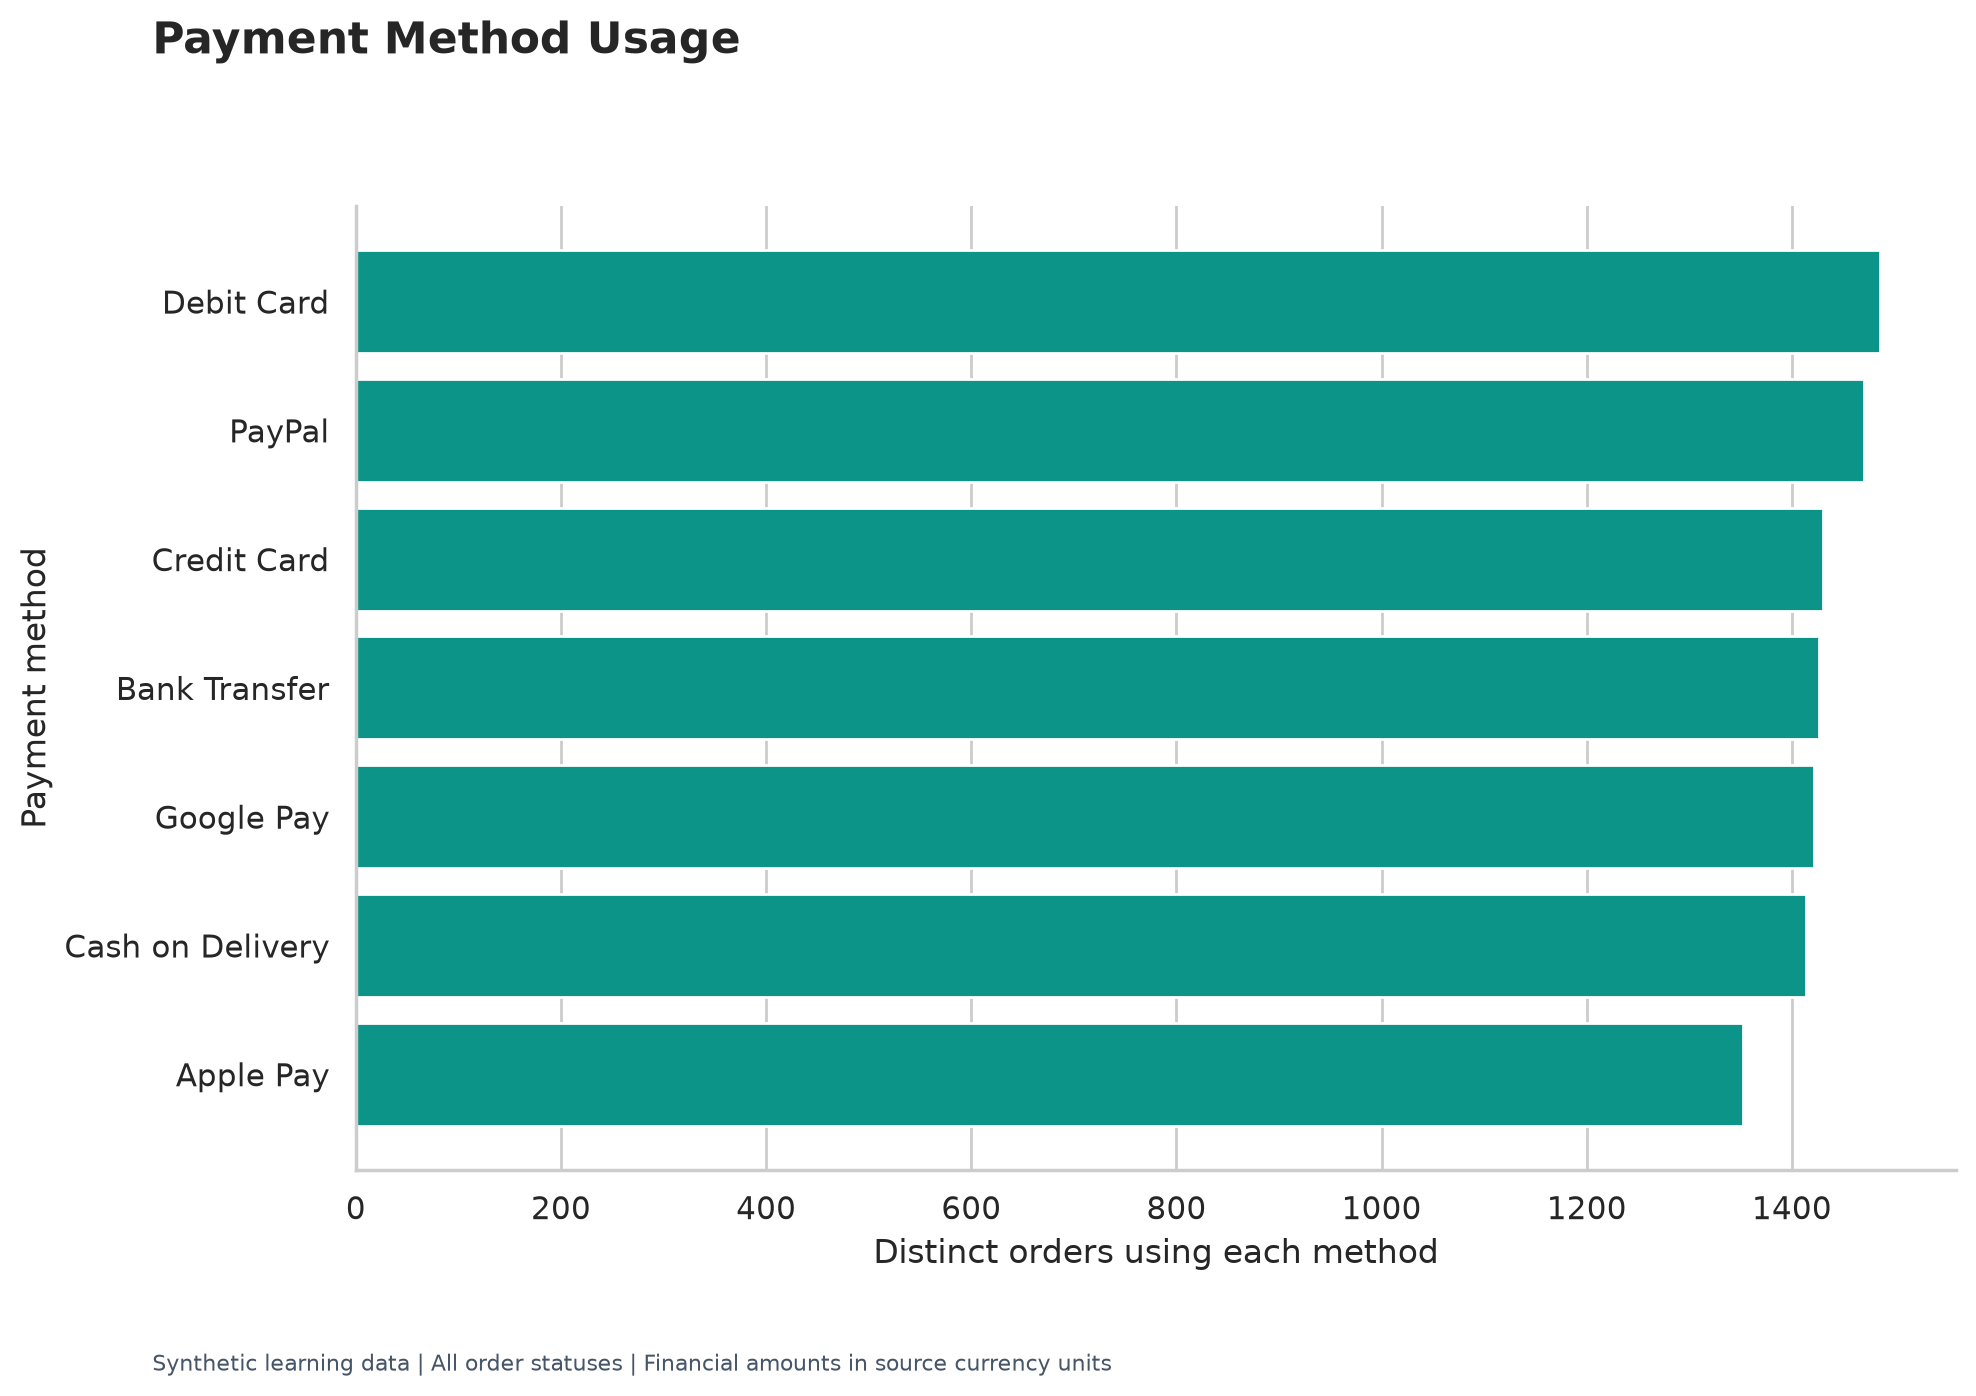

In [20]:
create_visualizations(eda_df, summaries)

for filename in CHART_FILENAMES:
    title = filename.replace(".png", "").replace("_", " ").title()
    display(Markdown(f"### {title}"))
    display(Image(filename=str(GRAPH_DIR / filename), width=850))

## 6. Findings and Interpretation

- Electronics leads recorded revenue and total profit.
- Middle East has the highest recorded regional revenue.
- Revenue is right-skewed, with many small transactions and fewer large ones.
- Discounts and row profit margins have a strong negative association.
- Monthly revenue peaks in October 2023 and subsequently declines.
  Order counts and dataset coverage need investigation before explaining why.
- Debit Card is the most-used payment method in this dataset.

## Limitations

These are observations from synthetic learning data.
They do not establish real-world customer preferences or causal effects.

All statuses are included in financial totals.
Customer names and return/cancellation reasons are unavailable.

In [21]:
if not CLEAN_FILE.is_file():
    raise FileNotFoundError("Run python main.py first.")

saved_df = pd.read_csv(
    CLEAN_FILE,
    dtype={"order_id": "string", "customer_id": "string"},
)

assert len(saved_df) == len(eda_df), "Row counts differ."
assert set(saved_df.columns) == set(eda_df.columns), "Columns differ."

# Compare business measures by order ID, independent of row order.
measures = [
    "order_id",
    "sales",
    "quantity",
    "discount",
    "profit",
    "revenue",
    "profit_margin_pct",
]

expected = (
    eda_df[measures]
    .sort_values("order_id")
    .reset_index(drop=True)
)

actual = (
    saved_df[measures]
    .sort_values("order_id")
    .reset_index(drop=True)
)

pd.testing.assert_frame_equal(
    expected,
    actual,
    check_dtype=False,
    check_exact=False,
    rtol=1e-9,
    atol=1e-8,
)

assert saved_df["order_id"].nunique() == summaries["kpis"]["unique_orders"]

assert np.isclose(
    saved_df["revenue"].sum(),
    summaries["kpis"]["total_revenue"],
    rtol=0,
    atol=0.01,
)

print("Notebook verification passed.")
print("Saved CSV and notebook business measures agree.")

Notebook verification passed.
Saved CSV and notebook business measures agree.
